In [ ]:
# 구글 드라이브 연결
from google.colab import drive
drive.mount('/content/drive')

# 운영체제(OS) 관련 기능 사용
import os

# 작업 위치를 step1 폴더로 이동
os.chdir('/content/drive/MyDrive/Colab Notebooks/Data_Analysis/DA_01')

# 현재 작업 위치 출력
print(os.getcwd())


In [ ]:
%run start.py

##  K-Means와 Elbow
- K-Means는 정답(y)이 없는 상태에서 **비슷한 데이터끼리 그룹으로 묶는 비지도학습**이다.
- `n_clusters=4`라면 4개 그룹으로 나누라는 뜻이다.
- 군집 번호 0, 1, 2, 3 자체에는 'VIP', '이탈위험' 같은 의미가 없어. **그룹의 특징을 보고 사람이 해석**해야한다.
- Elbow 방법은 K를 1,2,3... 바꾸면서 오차(군집 내부 거리)를 비교하고, **감소 폭이 크게 둔해지는 꺾이는 지점**을 K 후보로 선택하는 방법이다.


In [ ]:
# 정답 없이 비슷한 데이터끼리 K개의 군집으로 묶는 비지도학습
# 군집 수 K를 정할 때 오차 감소가 둔해지는 지점을 확인
# 비슷한 데이터끼리 자동으로 2개의 그룹으로 나누는 코드, 눈으로 봐도 2개의 그룹으로 나뉨
x = np.array([[1, 2], [1, 4], [1, 0],[10, 2], [10, 4], [10, 0]])
kmeans = KMeans(n_clusters=2) # 2개의 그룹으로 나눠
kmeans.fit(x) # 학습

print(f'cluster{kmeans.labels_}')
print(f'중심점: {kmeans.cluster_centers_}')
print(f'응집도: {kmeans.inertia_}')
# 중심점은 평균위치-대표값
# 응집도 - 잘모였나?값 작을수록 좋음

cluster[1 1 1 0 0 0]
중심점: [[10.  2.]
 [ 1.  2.]]
응집도: 16.0


##  엘보우 그래프

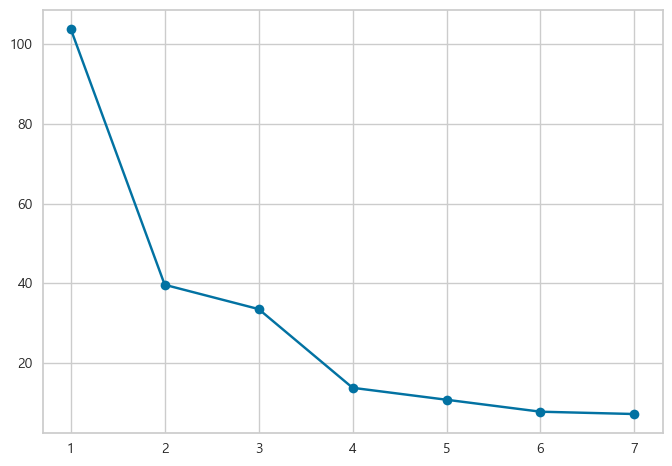

In [ ]:
# 정답 없이 비슷한 데이터끼리 K개의 군집으로 묶는 비지도학습
# 군집 수 K를 정할 때 오차 감소가 둔해지는 지점을 확인
# 클러스터 개수(k)를 몇 개로 할지 정하는 방법 = 엘보우 기법, 몇 개로 나누는 게 제일 좋나를 찾는 코드
# 몇 개 그룹으로 나눌지는 사람이 정해야 함, 그래서 1개 ~ 7개까지 다 해보고 비교하는 것
# i는 랜덤한 값, 1,2,3, ~7  응집도에 temp에 넣고 그래프를 그림
f = np.array([[3, 4], [1, 5], [7, 9],[5, 4], [6, 8], [2, 3],[4, 4],
              [4, 5], [2, 3], [6, 5],[5, 2], [4, 3], [8, 7],[5, 5]])
temp=[] # 빈 리스트 준비, 결과 저장
# 클러스터링 실행 1-7까지 다 나눠봄, inertia = 뭉친 정도 (작을수록 좋음)
for i in range(1,8):
    kmeans=KMeans(n_clusters=i)
    kmeans.fit(f)
    temp.append(kmeans.inertia_)
plt.plot(range(1,8),temp, marker='o')

# x축 = 클러스터 개수, y축 = 응집도, 꺾이는 지점 찾는 것-엘보우(팔꿈치), k = 3 또는 4가 적당
# inertia = 뭉친 정도 (작을수록 좋음)은 게 좋지만, 적당히 작은 지점(꺾이는 지점)을 선택한다.잘게 쪼개면 좋긴 한데, 적당히 쪼개는 게 최고(노력 대비 효과가 거의 없기 때문)
# 수박 = 데이터, 자르는 횟수 = 클러스터 개수(k), 먹기 편함 = inertia 감소 : 처음엔 효과 크고, 나중엔 별 차이 없는 그 순간이 꺾이는 지점

##  엘보우 그래프


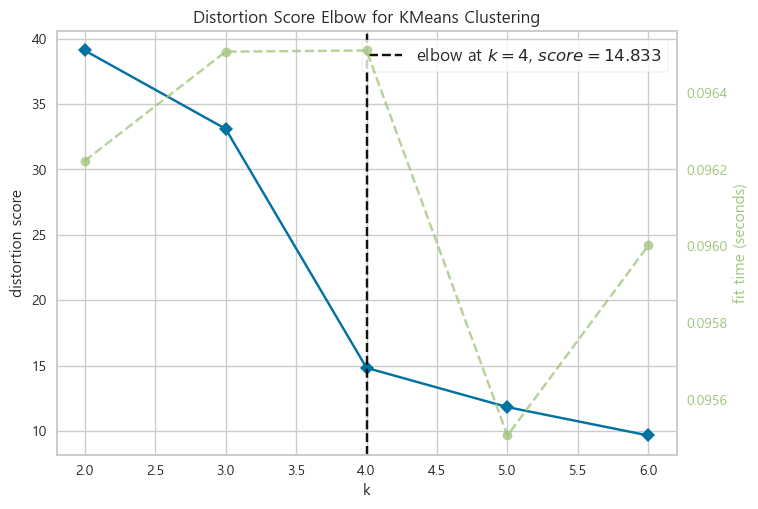

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [ ]:
# 정답 없이 비슷한 데이터끼리 K개의 군집으로 묶는 비지도학습
# 군집 수 K를 정할 때 오차 감소가 둔해지는 지점을 확인
# 클러스터 개수 몇 개가 좋은지 자동으로 찾아주는 코드
f = np.array([[3, 4], [1, 5], [7, 9],[5, 4], [6, 8], [2, 3],[4, 4],
              [4, 5], [2, 3], [6, 5],[5, 2], [4, 3], [8, 7],[5, 5]])

visualizer = KElbowVisualizer(KMeans(), k=(2,7)) # : 클러스터링 모델 준비, 클러스터 개수를 2개부터 6개까지 시험해봐라
visualizer.fit(f)  # 데이터 f로 학습(계산)
visualizer.show()  # 그래프로 보여줌, 파란색이 중요, 초록색-fit time(학습시간)참고만